In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
# Permite importar tu paquete de src/ sin instalarlo
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

# 05 · Torneo de modelos

Objetivo: elegir **uno o dos finalistas** para optimizar, con evidencia y **sin abrir la prueba**. Reglas:

1. **Mismos datos y mismos pliegues** para todos (los 5 pliegues estratificados del notebook 04).
2. **Dos líneas base**: la clase más frecuente y la **regla de negocio** ("llamar a quien no tiene seguro y tuvo daño").
3. **Guardar cada pliegue**, no solo el promedio, para comparar de a pares.

Los 5 modelos usan las variables base **y las 5 variables nuevas** (decisión del grupo, ver `reports/04_features.md`).
El torneo **descarta**, no corona: la optimización puede cambiar el orden.

## 0. Cargar los datos de entrenamiento

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from proyecto.config import PROCESSED_DIR, ROOT

train = pd.read_parquet(PROCESSED_DIR / "train.parquet")
print(f"entrenamiento: {train.shape[0]:,} filas x {train.shape[1]} columnas (la prueba NO se abre hoy)")

entrenamiento: 304,238 filas x 12 columnas (la prueba NO se abre hoy)


## 1. Validación común (los mismos pliegues para todos)

In [3]:
from proyecto.models.train import make_folds, split_xy

X, y = split_xy(train)
folds = make_folds(X, y)
print(f"{len(folds)} pliegues estratificados (los mismos del notebook 04); "
      f"cada pliegue de validación tiene ~{len(folds[0][1]):,} clientes")

5 pliegues estratificados (los mismos del notebook 04); cada pliegue de validación tiene ~60,848 clientes


## 2. Pipeline y métricas

- **Negocio (decide quién gana):** costo esperado por cliente con la matriz 5 a 1, llamando si P(interesado) > 1/6. Menor es mejor.
  Se reporta también el costo con umbral 0,5 y el % de clientes a los que se llamaría.
- **Técnicas:** **PR-AUC** (principal técnica), ROC-AUC, captura de interesados al llamar al 20/30/50 % mejor puntuado, recall,
  precisión, F1 y exactitud balanceada de "interesado", y calibración (log loss y Brier).

In [4]:
from proyecto.models.train import build_pipeline, candidates, cost_threshold

print(f"umbral de decisión de negocio: llamar si P(interesado) > {cost_threshold():.4f}")

umbral de decisión de negocio: llamar si P(interesado) > 0.1667


## 3. Candidatos

Dos líneas base y **5 modelos** con parámetros de partida fijos (sin optimizar):

In [5]:
models = candidates()
pipelines = {name: build_pipeline(model, use_engineered=True) for name, model in models.items()}
pd.DataFrame({"modelo": list(models), "clase": [m.__class__.__name__ for m in models.values()]}).set_index("modelo")

,clase
modelo,
línea base: clase más frecuente,DummyClassifier
línea base: regla de negocio,BusinessRuleClassifier
regresión logística,LogisticRegression
árbol de decisión,DecisionTreeClassifier
random forest,RandomForestClassifier
lightgbm,LGBMClassifier
xgboost,XGBClassifier


## 4. Correr el torneo (una fila por pliegue)

In [6]:
from proyecto.models.train import run_tournament

per_fold = run_tournament(pipelines, X, y, folds)
per_fold.to_csv(ROOT / "reports" / "05_torneo_folds.csv", index=False)
print("guardado: reports/05_torneo_folds.csv")

línea base: clase más frecuente    costo 0.6133 ± 0.0000 | PR-AUC 0.1227 | 0.3 s por pliegue


línea base: regla de negocio       costo 0.3729 ± 0.0017 | PR-AUC 0.2474 | 0.0 s por pliegue


regresión logística                costo 0.3389 ± 0.0031 | PR-AUC 0.3356 | 3.3 s por pliegue


árbol de decisión                  costo 0.3357 ± 0.0043 | PR-AUC 0.3246 | 1.9 s por pliegue


random forest                      costo 0.3336 ± 0.0033 | PR-AUC 0.3477 | 26.9 s por pliegue


lightgbm                           costo 0.3324 ± 0.0030 | PR-AUC 0.3469 | 2.4 s por pliegue


xgboost                            costo 0.3329 ± 0.0028 | PR-AUC 0.3472 | 8.5 s por pliegue
guardado: reports/05_torneo_folds.csv


## 5. Tabla resumen y variabilidad

In [7]:
from proyecto.models.train import summarize

summary = summarize(per_fold, metric="cost")
business = summary[["cost_mean", "cost_std", "cost_at_05_mean", "contact_rate_mean", "fit_seconds_mean"]].rename(columns={
    "cost_mean": "costo (media)", "cost_std": "± entre pliegues", "cost_at_05_mean": "costo con umbral 0,5",
    "contact_rate_mean": "% a llamar", "fit_seconds_mean": "segundos de ajuste"})
business.round(4)

,costo (media),± entre pliegues,"costo con umbral 0,5",% a llamar,segundos de ajuste
model,,,,,
lightgbm,0.3324,0.0030,0.6124,0.3630,2.3820
xgboost,0.3329,0.0028,0.6117,0.3603,8.5207
random forest,0.3336,0.0033,0.6133,0.3689,26.9427
árbol de decisión,0.3357,0.0043,0.6133,0.3621,1.9286
regresión logística,0.3389,0.0031,0.6132,0.3558,3.2982
línea base: regla de negocio,0.3729,0.0017,0.6133,0.4787,0.0169
línea base: clase más frecuente,0.6133,0.0000,0.6133,0.0000,0.3452


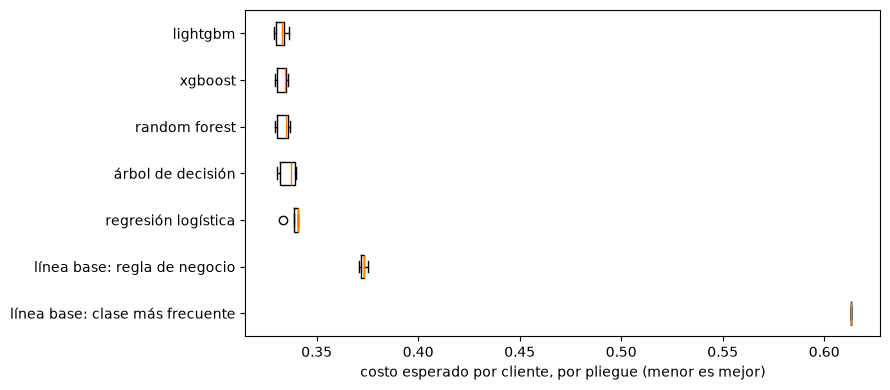

In [8]:
order = list(summary.index)
fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot([per_fold.loc[per_fold["model"] == n, "cost"] for n in order], vert=False, tick_labels=order, widths=0.5)
ax.invert_yaxis(); ax.set_xlabel("costo esperado por cliente, por pliegue (menor es mejor)")
plt.tight_layout(); plt.show()

### 5.1 Métricas técnicas (no solo la de negocio)

In [9]:
technical_cols = ["pr_auc", "roc_auc", "capture_20", "capture_30", "capture_50", "recall", "precision", "f1",
                  "balanced_accuracy", "log_loss", "brier"]
technical = summary[[f"{c}_mean" for c in technical_cols]]
technical.columns = technical_cols
technical.round(4)

,pr_auc,roc_auc,capture_20,capture_30,capture_50,recall,precision,f1,balanced_accuracy,log_loss,brier
model,,,,,,,,,,,
lightgbm,0.3469,0.8494,0.5570,0.7733,0.9887,0.8748,0.2956,0.4419,0.7917,0.2685,0.0879
xgboost,0.3472,0.8496,0.5568,0.7738,0.9887,0.8705,0.2964,0.4422,0.7908,0.2685,0.0879
random forest,0.3477,0.8496,0.5597,0.7726,0.9880,0.8814,0.2930,0.4398,0.7921,0.2692,0.0879
árbol de decisión,0.3246,0.8432,0.5366,0.7673,0.9862,0.8691,0.2944,0.4398,0.7890,0.2708,0.0886
regresión logística,0.3356,0.8461,0.5540,0.7646,0.9873,0.8563,0.2952,0.4390,0.7852,0.2705,0.0885
línea base: regla de negocio,0.2474,0.7840,0.4073,0.6107,0.9779,0.9771,0.2503,0.3986,0.7840,0.2869,0.0926
línea base: clase más frecuente,0.1227,0.5000,0.2006,0.2995,0.4995,0.0000,0.0000,0.0000,0.5000,0.3722,0.1076


### 5.2 ¿Coinciden los rankings de negocio y técnico?

Posiciones (1 = mejor) por cada métrica. Un modelo puede ordenar bien (PR-AUC) y aun así decidir peor (costo) si sus
probabilidades están mal calibradas, porque el umbral 1/6 supone probabilidades honestas.

In [10]:
ranks = pd.DataFrame({
    "costo": summary["cost_mean"].rank(),
    "PR-AUC": (-summary["pr_auc_mean"]).rank(),
    "ROC-AUC": (-summary["roc_auc_mean"]).rank(),
    "F1": (-summary["f1_mean"]).rank(),
    "log loss": summary["log_loss_mean"].rank(),
}).astype(int)
ranks

,costo,PR-AUC,ROC-AUC,F1,log loss
model,,,,,
lightgbm,1,3,3,2,2
xgboost,2,2,2,1,1
random forest,3,1,1,4,3
árbol de decisión,4,5,5,3,5
regresión logística,5,4,4,5,4
línea base: regla de negocio,6,6,6,6,6
línea base: clase más frecuente,7,7,7,7,7


### 5.3 Control: ¿las variables nuevas ayudan a los modelos simples?

Es el motivo para usarlas en el torneo (`reports/04_features.md`). Se miden la regresión logística y el árbol **sin** las variables
nuevas, con los mismos pliegues.

In [11]:
from proyecto.models.train import improvement_over_noise

control = run_tournament({f"{n} (sin variables nuevas)": build_pipeline(models[n], use_engineered=False)
                          for n in ["regresión logística", "árbol de decisión"]}, X, y, folds)
rows = []
for n in ["regresión logística", "árbol de decisión"]:
    base = control.loc[control["model"] == f"{n} (sin variables nuevas)"]
    with_new = per_fold.loc[per_fold["model"] == n]
    r = improvement_over_noise(base["cost"], with_new["cost"])
    rows.append({"modelo": n, "costo sin nuevas": base["cost"].mean(), "costo con nuevas": with_new["cost"].mean(),
                 "mejora / ruido": r["improvement_over_noise"], "pliegues que gana": r["folds_won"],
                 "PR-AUC sin": base["pr_auc"].mean(), "PR-AUC con": with_new["pr_auc"].mean()})
pd.DataFrame(rows).set_index("modelo").round(4)

regresión logística (sin variables nuevas) costo 0.3542 ± 0.0012 | PR-AUC 0.3179 | 3.3 s por pliegue


árbol de decisión (sin variables nuevas) costo 0.3365 ± 0.0035 | PR-AUC 0.3184 | 2.6 s por pliegue


,costo sin nuevas,costo con nuevas,mejora / ruido,pliegues que gana,PR-AUC sin,PR-AUC con
modelo,,,,,,
regresión logística,0.3542,0.3389,4.8967,5,0.3179,0.3356
árbol de decisión,0.3365,0.3357,0.1804,4,0.3184,0.3246


## 6. Comparación pareada

In [12]:
from proyecto.models.train import BASELINE_PRIOR, BASELINE_RULE, compare_paired

real_models = [m for m in summary.index if m not in (BASELINE_PRIOR, BASELINE_RULE)]
best3 = real_models[:3]
pairs = []
for i in range(len(best3)):
    for j in range(i + 1, len(best3)):
        a = per_fold.loc[per_fold["model"] == best3[i], "cost"].to_numpy()
        b = per_fold.loc[per_fold["model"] == best3[j], "cost"].to_numpy()
        pairs.append({"mejor": best3[i], "contra": best3[j], **compare_paired(a, b)})
rule = per_fold.loc[per_fold["model"] == BASELINE_RULE, "cost"].to_numpy()
for m in best3:
    pairs.append({"mejor": m, "contra": BASELINE_RULE,
                  **compare_paired(per_fold.loc[per_fold["model"] == m, "cost"].to_numpy(), rule)})
pd.DataFrame(pairs).round(4)

,mejor,contra,mean_difference,folds_won,difference_over_noise
0,lightgbm,xgboost,0.0005,3 de 5,0.4991
1,lightgbm,random forest,0.0011,4 de 5,1.2491
2,xgboost,random forest,0.0006,4 de 5,0.7892
3,lightgbm,línea base: regla de negocio,0.0405,5 de 5,17.7704
4,xgboost,línea base: regla de negocio,0.0400,5 de 5,22.8460
5,random forest,línea base: regla de negocio,0.0394,5 de 5,16.3772


## 7. ¿Cuánto vale la diferencia?

No hay todavía una cifra real de cuántos clientes evalúa el negocio al mes, así que se expresa **por cada 10.000 clientes
evaluados**, en unidades de costo (1 unidad = una llamada sin éxito; 5 = un interesado no contactado). El grupo puede reemplazar
`CLIENTS` por su volumen real.

In [13]:
CLIENTS = 10_000
per_10k = (summary["cost_mean"] * CLIENTS).rename("costo por 10.000 clientes (unidades)").to_frame()
per_10k["ahorro frente a la regla de negocio"] = per_10k.iloc[:, 0].loc[BASELINE_RULE] - per_10k.iloc[:, 0]
per_10k.round(0)

,costo por 10.000 clientes (unidades),ahorro frente a la regla de negocio
model,,
lightgbm,3324.0,405.0
xgboost,3329.0,400.0
random forest,3336.0,394.0
árbol de decisión,3357.0,372.0
regresión logística,3389.0,340.0
línea base: regla de negocio,3729.0,0.0
línea base: clase más frecuente,6133.0,-2403.0


## 8. Finalistas

**Lo que muestran los resultados** (5 pliegues, ~60.800 clientes de validación cada uno):

- **Los 5 modelos vencen a la regla de negocio en los 5 pliegues.** LightGBM cuesta 0,3324 por cliente, frente a 0,3729 de la regla.
  - Es 0,0405 menos, unas 18 veces el ruido.
  - Equivale a 405 unidades de costo menos por cada 10.000 clientes, un 11 % menos.
  - Además llama a menos gente: el 36 % de los clientes en vez del 48 %.
- **El umbral de negocio es imprescindible.** Con umbral 0,5 todos los modelos cuestan lo mismo que no llamar a nadie (~0,613), porque
  casi ningún cliente supera el 50 % de probabilidad. Con 1/6 encuentran el 87 % de los interesados.
- **Los tres modelos de árboles en conjunto (LightGBM, XGBoost y random forest) están prácticamente empatados.**
  - LightGBM frente a XGBoost: diferencia / ruido de 0,50, y LightGBM gana en 3 de 5 pliegues. Es un empate.
  - LightGBM frente a random forest: 1,25, y LightGBM gana en 4 de 5 pliegues.
  - Random forest tiene el mejor PR-AUC (0,348), pero tarda 11 veces más que LightGBM (27 s frente a 2,4 s por pliegue).
- **Las variables nuevas sí ayudan a la regresión logística:** su costo baja de 0,3542 a 0,3389 (mejora / ruido 4,9; gana en 5 de 5 pliegues).
  Al árbol casi no lo ayudan (0,18). Esto confirma el motivo de la decisión del grupo.

| Finalista | Por qué | Qué podría cambiar con la optimización |
|---|---|---|
| **LightGBM** | El costo más bajo (0,3324 ± 0,0030), el más rápido de los tres de árboles en conjunto (2,4 s por pliegue) y gana a random forest en 4 de 5 pliegues | Número de árboles, hojas, tasa de aprendizaje y regularización; con 300.000 filas hay margen para más árboles |
| **XGBoost** | Empatado con LightGBM (0,3329; diferencia / ruido 0,50); el mejor en F1 y en log loss (mejor calibrado, importante porque la decisión usa un umbral sobre la probabilidad) | Profundidad, tasa de aprendizaje y submuestreo; podría superar a LightGBM |

**Descartados:**
- Random forest: es igual de bueno pero 11 veces más lento.
- Árbol y regresión logística: cuestan 0,0033 y 0,0065 más que LightGBM. Quedan como referencias interpretables.

**Por qué el torneo no elige un campeón:** las diferencias entre los finalistas son menores que el ruido entre pliegues, y la
optimización (etapa 06) puede cambiar el orden. Solo la prueba final, que se abre una vez en la etapa 07, dice qué tan bueno es el
modelo elegido.

**Decisión del grupo (2026-10-31): se elige LightGBM** (costo más bajo y el más rápido). Pasa solo a la etapa 06; XGBoost queda como referencia.

## Entregable de esta etapa

- [x] Al menos **3 modelos y una línea base**, evaluados en **los mismos pliegues** (5 modelos y 2 líneas base).
- [x] Una fila **por pliegue** guardada para cada modelo (`reports/05_torneo_folds.csv`).
- [x] **Métricas técnicas** de cada modelo y la comparación entre el ranking de negocio y el técnico.
- [x] Comparación pareada de los mejores (pliegues que gana y diferencia / ruido).
- [x] La diferencia traducida a **volumen** (por 10.000 clientes).
- [x] **1–2 finalistas** justificados en `reports/05_torneo.md`.
- [x] El código reutilizable está en `src/proyecto/models/` y el notebook solo lo llama.